# E0.3c — Bollinger detector onset and classification (research prototype)

**Scope:** Full-year BTCUSDT, 4H/1H/15m/5m. The **frozen V0** walk detector is compared with four event-trigger alternatives. **This is not yet a trading backtest.**

### Critical definitions

- *Reference movement*: directionally large closing-price displacement over `LOOKBACK_BARS`, exceeding `K_ATR` times previously known ATR. Confirmation happens **after** displacement; `onset` is assigned retrospectively to the beginning of that lookback window. This is an **offline proxy**, not definitive walk ground truth.
- *Alarm*: a rule observable at a candle close. V0 marks confirmed walks; V1/V2 mark near-band runs; V3 checks a previous-band close crossing; V4 uses shifted rolling tail quantiles.
- *Matched alarm*: same direction and between reference onset and `MAX_LAG_BARS` after onset, one-to-one. This scoring intentionally rewards earlier triggers but may associate unrelated fluctuations. Sensitivity tests required.
- *False alarms* in these tables are **unmatched alarms relative to the chosen reference**, not proven bad trades or calibrated CFAR Pfa.

**No parameter selection on full-year results.** Use 2025 descriptively; reserve genuinely untouched future periods for final validation.

## Setup and import the existing verified 5m loader

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from walk_states import bollinger_from_5m, detect_walk_states
from e03_analysis import (align_to_5m, occupancy, next_walk_probabilities,
                          cross_overlap, conditional_lift, plot_pair)

import requests
from pathlib import Path
import json

START, END = "2025-01-01", "2026-01-01"
TIMEFRAMES = {"4H":"4h", "1H":"1h", "15m":"15min", "5m":"5min"}
PARAMS = dict(near=0.15, confirm_bars=3, exit_bars=2, slope_bars=3)

NOV_START = "2025-11-13"
NOV_END = "2025-11-23"

CONFIGS = {"1D":"1D", "1H":"1h", "15m":"15min", "5m":"5min"}
WINDOW = 20
NEAR = 0.15
CONFIRM_BARS = 3
EXIT_BARS = 2
SLOPE_BARS = 3

REPO = Path("/media/ata/Data/personal/binbot")
DATA_DIR = REPO / "research" / "sentiment_price" / "data"
CACHE_DIR = DATA_DIR / "btcusdt_5m_batches"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Warm-up before 2025 and a buffer for forward-return labels.
START = pd.Timestamp("2024-12-30", tz="UTC")
END = pd.Timestamp("2026-01-02", tz="UTC")  # exclusive

STEP_MS = 5 * 60 * 1000
START_MS = int(START.timestamp() * 1000)
END_MS = int(END.timestamp() * 1000)

print("Expected candles:", (END_MS - START_MS) // STEP_MS)

# Paste the verified 5m OHLCV loader from 02_price_features.ipynb or E03 here.
# TODO: paste verified 5-minute data loading code from 02_price_features.ipynb
all_candles = []
cursor = START_MS

with requests.Session() as session:
    while cursor < END_MS:
        batch_end = min(cursor + 1000 * STEP_MS, END_MS)
        cache_file = CACHE_DIR / f"{cursor}_{batch_end}.json"

        if cache_file.exists():
            batch = json.loads(cache_file.read_text())
        else:
            response = session.get(
                "https://api.binance.com/api/v3/klines",
                params={
                    "symbol": "BTCUSDT",
                    "interval": "5m",
                    "timeZone": "0",
                    "startTime": cursor,
                    "endTime": batch_end - 1,
                    "limit": 1000,
                },
                timeout=30,
            )
            response.raise_for_status()
            batch = response.json()

        if not isinstance(batch, list) or not batch:
            raise ValueError(f"Unexpected response at {cursor}: {batch}")

        # Require every expected candle; do not silently fill gaps.
        expected_opens = list(range(cursor, batch_end, STEP_MS))
        actual_opens = [int(row[0]) for row in batch]

        if actual_opens != expected_opens:
            raise ValueError(
                f"Missing, duplicate or unexpected candles in batch {cursor}"
            )

        if not cache_file.exists():
            temporary = cache_file.with_suffix(".tmp")
            temporary.write_text(json.dumps(batch))
            temporary.replace(cache_file)
            time.sleep(0.2)

        all_candles.extend(batch)
        cursor = batch_end

        print(
            f"\rLoaded {len(all_candles):,} candles",
            end="",
            flush=True,
        )

print("\nDownload/cache loading complete.")
columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "trade_count",
    "taker_buy_volume", "taker_buy_quote_volume", "ignore",
]

bars = pd.DataFrame(all_candles, columns=columns)

bars["open_time"] = pd.to_datetime(bars["open_time"], unit="ms", utc=True)
bars["close_time"] = pd.to_datetime(bars["close_time"], unit="ms", utc=True)

numeric = [
    "open", "high", "low", "close", "volume", "quote_volume",
    "trade_count", "taker_buy_volume", "taker_buy_quote_volume",
]
bars[numeric] = bars[numeric].apply(pd.to_numeric, errors="raise")
bars = bars.set_index("open_time").sort_index()

expected_index = pd.date_range(
    START, END - pd.Timedelta(minutes=5), freq="5min"
)

assert bars.index.is_unique
assert bars.index.equals(expected_index), "Unexpected candle coverage"
assert bars[numeric].notna().all().all()
assert (bars[["open", "high", "low", "close"]] > 0).all().all()
assert (bars["low"] <= bars[["open", "close"]].min(axis=1)).all()
assert (bars["high"] >= bars[["open", "close"]].max(axis=1)).all()
assert (bars["volume"] >= 0).all()
assert "bars" in globals(), "Load your existing 5m OHLCV dataframe as bars first"
assert "bars" in globals(), "First load your verified 5-minute OHLCV dataframe as `bars`."
assert {"open","high","low","close","volume"}.issubset(bars.columns)
print('Rows:',len(bars),'Range:',bars.index.min(),bars.index.max())

Expected candles: 105984
Loaded 105,984 candles
Download/cache loading complete.
Rows: 105984 Range: 2024-12-30 00:00:00+00:00 2026-01-01 23:55:00+00:00


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from walk_states import bollinger_from_5m
from e03c_analysis import (price_impulse_references, candidate_alarms, detector_report,
                            causal_atr, VARIANTS)

# Provide `bars`: five-minute OHLCV, indexed by candle OPEN in UTC.
# Copy ONLY the verified loading cell from 02_price_features.ipynb.
assert 'bars' in globals(), "Load the existing 5m dataframe into bars first"
assert {'open','high','low','close','volume'} <= set(bars.columns)


## Frozen comparison settings

In [3]:
START, END = '2025-01-01', '2026-01-01'
TIMEFRAMES={'4H':'4h','1H':'1h','15m':'15min','5m':'5min'}
# Reference parameters expressed in bars, not elapsed hours
LOOKBACK_BARS=3
K_ATR=1.5
COOLDOWN_BARS=6
MAX_LAG_BARS=6
results={}; rows=[]
for label,step in TIMEFRAMES.items():
    bb=bollinger_from_5m(bars,START,END,resolution=step,window=20,num_std=2)
    ref=price_impulse_references(bb,lookback=LOOKBACK_BARS,threshold_atr=K_ATR,
                                  cooldown_bars=COOLDOWN_BARS)
    results[label]={'bb':bb,'references':ref,'variants':{}}
    for variant in VARIANTS:
        report,alarms,matches,unmatched=detector_report(bb,ref,variant,
                                                          max_lag_bars=MAX_LAG_BARS)
        rows.append({'tf':label,**report})
        results[label]['variants'][variant]={'alarms':alarms,'matches':matches,'unmatched':unmatched}
comparison=pd.DataFrame(rows).set_index(['tf','variant'])
display(comparison.round(3))

references  alarms  matched  detection_rate  \
tf  variant                                                            
4H  V0_frozen                   149      75       60           0.403   
    V1_one_bar                  149     222      108           0.725   
    V2_near_no_slope            149     258      116           0.779   
    V3_prior_band_cross         149     146       95           0.638   
    V4_adaptive                 149       5        5           0.034   
1H  V0_frozen                   534     326      232           0.434   
    V1_one_bar                  534     965      389           0.728   
    V2_near_no_slope            534    1103      421           0.788   
    V3_prior_band_cross         534     672      363           0.680   
    V4_adaptive                 534      14       11           0.021   
15m V0_frozen                  2280    1252      845           0.371   
    V1_one_bar                 2280    4023     1611           0.707   
    V2_near_no_slope           2280    4605     1772           0.777   
    V3_prior_band_cross        2280    2669     1428           0.626   
    V4_adaptive                2280      44       39           0.017   
5m  V0_frozen                  8201    4040     2810           0.343   
    V1_one_bar                 8201   12168     5454           0.665   
    V2_near_no_slope           8201   13880     6037           0.736   
    V3_prior_band_cross        8201    8026     4724           0.576   
    V4_adaptive                8201     104       90           0.011   

                         alarm_precision  unmatched_alarms  unmatched_per_day  \
tf  variant                                                                     
4H  V0_frozen                      0.800                15              0.041   
    V1_one_bar                     0.486               114              0.312   
    V2_near_no_slope               0.450               142              0.389   
    V3_prior_band_cross            0.651                51              0.140   
    V4_adaptive                    1.000                 0              0.000   
1H  V0_frozen                      0.712                94              0.258   
    V1_one_bar                     0.403               576              1.578   
    V2_near_no_slope               0.382               682              1.869   
    V3_prior_band_cross            0.540               309              0.847   
    V4_adaptive                    0.786                 3              0.008   
15m V0_frozen                      0.675               407              1.115   
    V1_one_bar                     0.400              2412              6.608   
    V2_near_no_slope               0.385              2833              7.762   
    V3_prior_band_cross            0.535              1241              3.400   
    V4_adaptive                    0.886                 5              0.014   
5m  V0_frozen                      0.696              1230              3.370   
    V1_one_bar                     0.448              6714             18.395   
    V2_near_no_slope               0.435              7843             21.488   
    V3_prior_band_cross            0.589              3302              9.047   
    V4_adaptive                    0.865                14              0.038   

                         median_lag_bars  
tf  variant                               
4H  V0_frozen                        4.5  
    V1_one_bar                       3.0  
    V2_near_no_slope                 3.0  
    V3_prior_band_cross              3.0  
    V4_adaptive                      3.0  
1H  V0_frozen                        5.0  
    V1_one_bar                       3.0  
    V2_near_no_slope                 3.0  
    V3_prior_band_cross              3.0  
    V4_adaptive                      3.0  
15m V0_frozen                        4.0  
    V1_one_bar                       3.0  
    V2_near_no_slope                 3.0  
    V3_prior

## Detection versus unmatched alarms

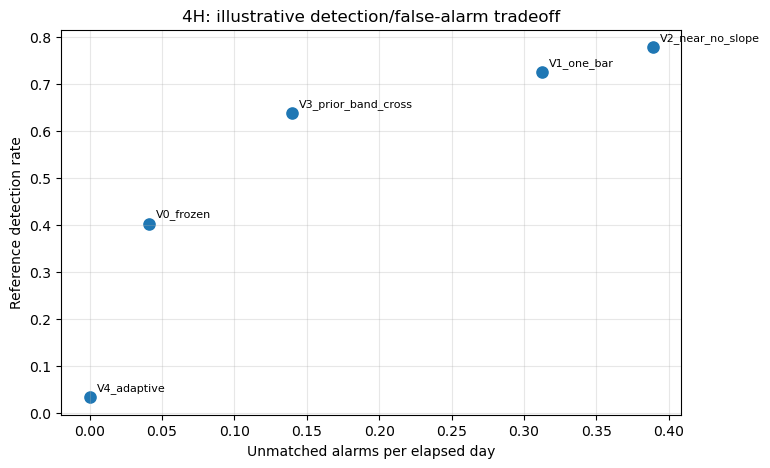

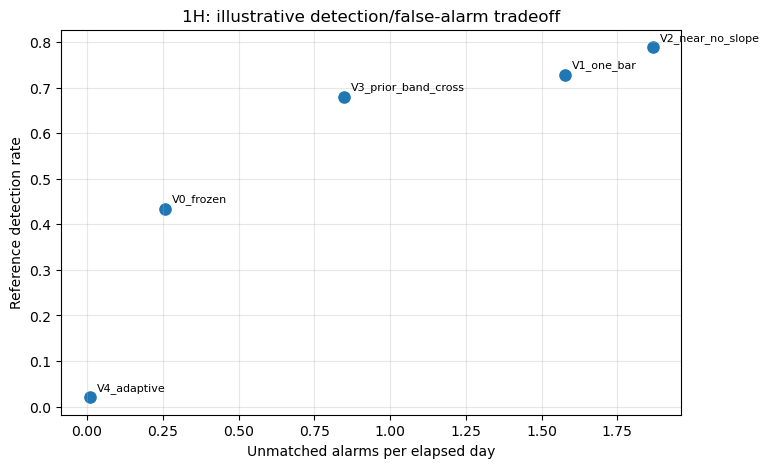

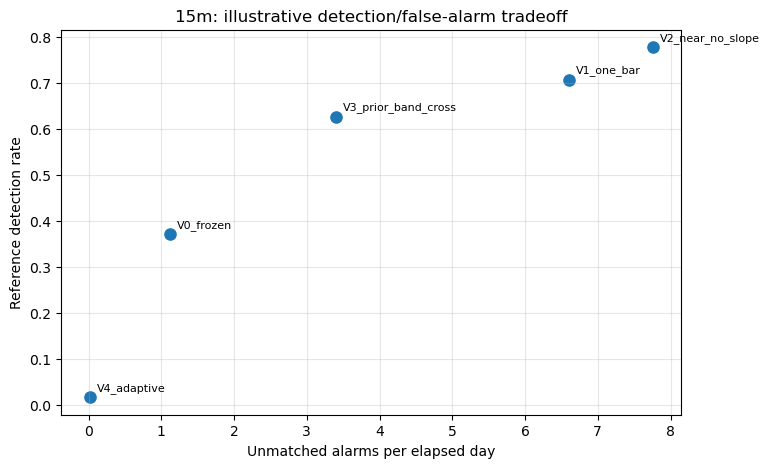

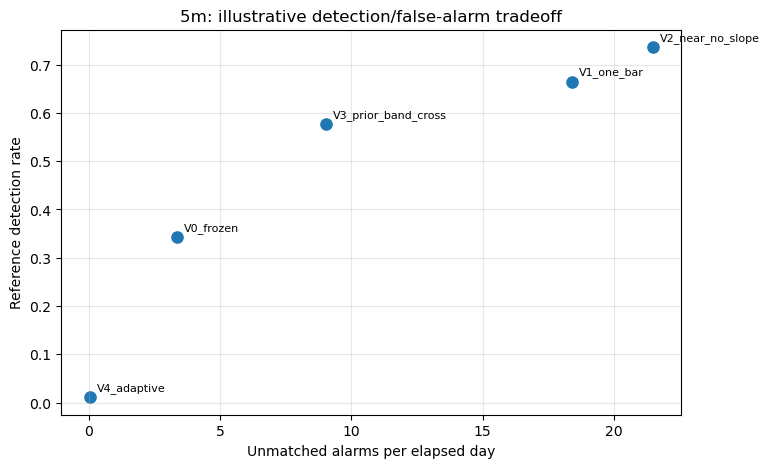

In [4]:
for tf in TIMEFRAMES:
    d=comparison.loc[tf]
    fig,ax=plt.subplots(figsize=(8,5))
    ax.scatter(d['unmatched_per_day'],d['detection_rate'],s=65)
    for name,row in d.iterrows():
        ax.annotate(name,(row['unmatched_per_day'],row['detection_rate']),xytext=(5,5),textcoords='offset points',fontsize=8)
    ax.set(xlabel='Unmatched alarms per elapsed day',ylabel='Reference detection rate',
           title=f'{tf}: illustrative detection/false-alarm tradeoff')
    ax.grid(alpha=.3);plt.show()

## Visual audit: one resolution at a time (change selected period freely)

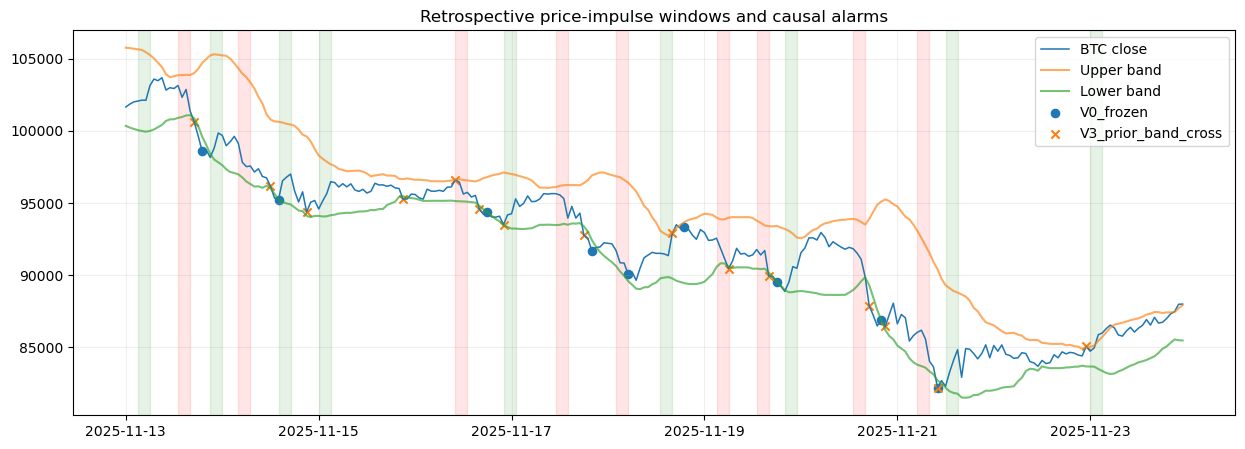

In [5]:
TF='1H'; VIEW_START='2025-11-13'; VIEW_END='2025-11-23'
run=results[TF];bb=run['bb'].loc[VIEW_START:VIEW_END]
fig,ax=plt.subplots(figsize=(15,5))
ax.plot(bb.index,bb.close,label='BTC close',lw=1.1)
ax.plot(bb.index,bb.bb_upper,label='Upper band',alpha=.65)
ax.plot(bb.index,bb.bb_lower,label='Lower band',alpha=.65)
ref=run['references']
ref=ref[(ref.onset>=pd.Timestamp(VIEW_START,tz='UTC'))&(ref.onset<=pd.Timestamp(VIEW_END,tz='UTC'))]
for e in ref.itertuples():
    ax.axvspan(e.onset,e.detected_at,alpha=.10,color='green' if e.direction=='UPPER_WALK' else 'red')
for v,mark in [('V0_frozen','o'),('V3_prior_band_cross','x')]:
    a=run['variants'][v]['alarms']
    a=a[(a.time>=pd.Timestamp(VIEW_START,tz='UTC'))&(a.time<=pd.Timestamp(VIEW_END,tz='UTC'))]
    ax.scatter(a.time,run['bb'].close.reindex(a.time),label=v,marker=mark,s=35)
ax.legend();ax.grid(alpha=.2);ax.set_title('Retrospective price-impulse windows and causal alarms')
plt.show()

## Required before tuning

1. Inspect different months, both directions and all timeframes.
2. Vary **reference** parameters independently (lookback, ATR multiplier, cooldown); check that variant rankings are stable.
3. Vary matching tolerance; unmatched alarms may simply precede the reference onset or indicate price patterns it does not label.
4. Add an independent sustained-walk reference based on **price path**, with onset/confirmation/exit and censoring, not on V0 Bollinger states.
5. Evaluate in chronological train/validation/test splits, with uncertainty clustered by movement episode and sensitivity to market regime.
6. Only then attempt adaptive score calibration to a target false-alarm budget, and compare missed price displacement / detection latency.
